# 02. Làm sạch dữ liệu, xử lý mất cân bằng, mã hóa và chuẩn hóa

In [1]:
import sys; sys.path.append('..')
from src.common import *
import warnings; warnings.filterwarnings('ignore')
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

In [2]:
raw = pd.read_csv(DATA / 'heart_raw.csv')
df = raw.copy()
log = []  # ghi lại từng quyết định xử lý

## 1. Quyết định làm sạch
| # | Vấn đề | Cách xử lý | Lý do |
|---|---|---|---|
| 1 | 1 dòng trùng lặp | Xóa | Dòng lặp làm một bệnh nhân được đếm hai lần, có nguy cơ rơi vào cả train lẫn test |
| 2 | `ca = 4` (5 dòng trong file gốc, còn 4 sau khi xóa dòng trùng) | Đặt NaN | Ngoài khoảng hợp lệ 0 đến 3 |
| 3 | `thal = 0` (2 dòng) | Đặt NaN | Ngoài khoảng hợp lệ 1 đến 3 |
| 4 | NaN sau bước 2, 3 | Điền trong Pipeline (median cho số, mode cho phân loại) | Fit imputer chỉ trên train để tránh rò rỉ dữ liệu |
| 5 | Ngoại lai (IQR) | Giữ nguyên, thống kê bên dưới | Giá trị đều khả dĩ về y học, bộ dữ liệu nhỏ nên xóa sẽ mất thông tin |
| 6 | Nhãn bị đảo | `HeartDisease = 1 - target` | Xem notebook 01 mục 5 |

`chol` và `trestbps` không có giá trị 0 trong bản này (khác bộ Heart Failure 918 dòng), nên không cần xử lý mã 0.

In [3]:
n0 = len(df)
df = df.drop_duplicates().reset_index(drop=True)
log.append(('Xóa dòng trùng', n0 - len(df)))
bad_ca = (df.ca == 4); bad_thal = (df.thal == 0)
df.loc[bad_ca, 'ca'] = np.nan; df.loc[bad_thal, 'thal'] = np.nan
log += [('ca=4 -> NaN', int(bad_ca.sum())), ('thal=0 -> NaN', int(bad_thal.sum()))]
df[TARGET] = 1 - df['target']
df = df.drop(columns='target')
pd.DataFrame(log, columns=['Thao tác', 'Số dòng'])

,Thao tác,Số dòng
0,Xóa dòng trùng,1
1,ca=4 -> NaN,4
2,thal=0 -> NaN,2


### Bảng trước và sau khi làm sạch

In [4]:
before = pd.DataFrame({'Trước': [raw.shape[0], raw.duplicated().sum(), int((raw.ca==4).sum()+(raw.thal==0).sum()), raw.isna().sum().sum()],
                       }, index=['Số dòng', 'Dòng trùng', 'Giá trị mã sai (ca=4, thal=0)', 'NaN'])
after = pd.Series([df.shape[0], df.duplicated().sum(), 0, int(df.isna().sum().sum())], index=before.index)
before['Sau'] = after; before

,Trước,Sau
Số dòng,303,302
Dòng trùng,1,0
"Giá trị mã sai (ca=4, thal=0)",7,0
NaN,0,6


### Ngoại lai theo quy tắc IQR (chỉ thống kê, không xóa)

In [5]:
rows = []
for c in ['age','trestbps','chol','thalach','oldpeak']:
    q1, q3 = df[c].quantile([.25, .75]); i = q3 - q1
    lo, hi = q1 - 1.5*i, q3 + 1.5*i
    rows.append((c, round(lo,1), round(hi,1), int(((df[c] < lo) | (df[c] > hi)).sum()), df[c].min(), df[c].max()))
pd.DataFrame(rows, columns=['Cột','Ngưỡng dưới','Ngưỡng trên','Số ngoại lai','Min','Max'])

,Cột,Ngưỡng dưới,Ngưỡng trên,Số ngoại lai,Min,Max
0,age,28.5,80.5,0,29.0,77.0
1,trestbps,90.0,170.0,9,94.0,200.0
2,chol,115.4,370.4,5,126.0,564.0
3,thalach,84.1,215.1,1,71.0,202.0
4,oldpeak,-2.4,4.0,5,0.0,6.2


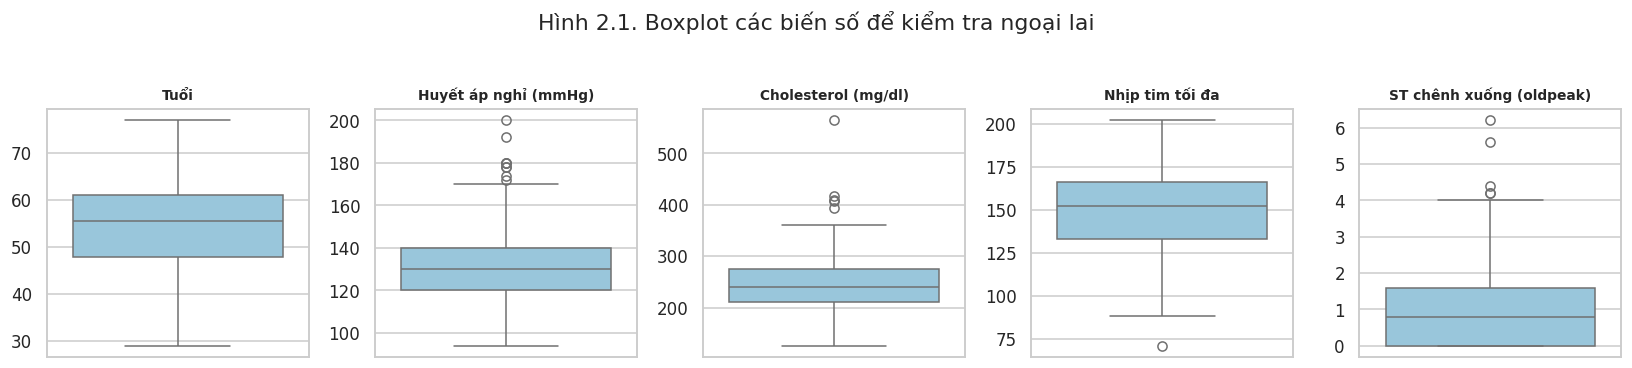

In [6]:
fig, ax = plt.subplots(1, 5, figsize=(15, 3.2))
for a, c in zip(ax, ['age','trestbps','chol','thalach','oldpeak']):
    sns.boxplot(y=df[c], ax=a, color='#8ecae6'); a.set_title(VN[c], fontsize=9); a.set_ylabel('')
plt.suptitle('Hình 2.1. Boxplot các biến số để kiểm tra ngoại lai', y=1.04)
savefig('fig_2_1_boxplot_ngoai_lai')

In [7]:
df.to_csv(DATA / 'heart_clean.csv', index=False)
print('Đã lưu data/heart_clean.csv', df.shape)

Đã lưu data/heart_clean.csv (302, 14)


## 2. Kiểm tra mất cân bằng lớp

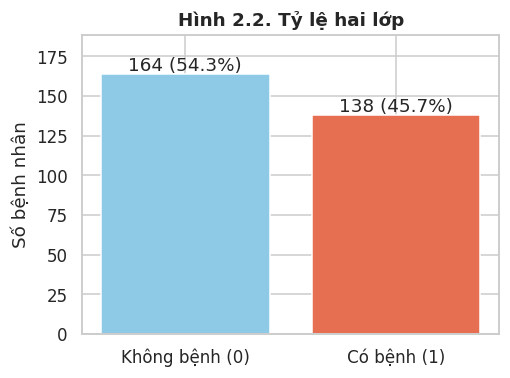

{0: 54.3, 1: 45.7} | tỷ lệ lớp lớn/lớp nhỏ = 1.19


In [8]:
vc = df[TARGET].value_counts().sort_index(); pct = (vc / len(df) * 100).round(1)
fig, ax = plt.subplots(figsize=(4.8, 3.6))
b = ax.bar(['Không bệnh (0)', 'Có bệnh (1)'], vc.values, color=['#8ecae6', '#e76f51'])
for r, v, p in zip(b, vc.values, pct.values): ax.text(r.get_x()+r.get_width()/2, v+2, f'{v} ({p}%)', ha='center')
ax.set_ylabel('Số bệnh nhân'); ax.set_title('Hình 2.2. Tỷ lệ hai lớp'); ax.set_ylim(0, vc.max()*1.15)
savefig('fig_2_2_ty_le_lop')
print(pct.to_dict(), '| tỷ lệ lớp lớn/lớp nhỏ =', round(vc.max()/vc.min(), 2))

Tỷ lệ lớp gần cân bằng. Ta vẫn **so sánh thực nghiệm** ba cách: không xử lý, `class_weight='balanced'` và SMOTE. Đánh giá bằng cross-validation lặp 5 fold x 3 lần trên **tập train** (SMOTE nằm trong pipeline nên chỉ sinh mẫu trên fold train, không rò rỉ sang fold kiểm tra).

In [9]:
X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
scoring = ['accuracy', 'precision', 'recall', 'f1']
res = []
for mname, mk in {'Logistic Regression': lambda cw: LogisticRegression(max_iter=2000, class_weight=cw),
                  'Random Forest': lambda cw: RandomForestClassifier(n_estimators=300, class_weight=cw, random_state=RANDOM_STATE)}.items():
    for strat in ['Không xử lý', 'class_weight', 'SMOTE']:
        if strat == 'SMOTE':
            pipe = ImbPipeline([('prep', make_preprocessor()), ('smote', SMOTE(random_state=RANDOM_STATE)), ('clf', mk(None))])
        else:
            pipe = Pipeline([('prep', make_preprocessor()), ('clf', mk('balanced' if strat == 'class_weight' else None))])
        s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
        res.append({'Mô hình': mname, 'Cách xử lý': strat, **{k: round(s['test_'+k].mean(), 3) for k in scoring}})
imb = pd.DataFrame(res); imb

,Mô hình,Cách xử lý,accuracy,precision,recall,f1
0,Logistic Regression,Không xử lý,0.845,0.858,0.800,0.825
1,Logistic Regression,class_weight,0.853,0.852,0.830,0.839
2,Logistic Regression,SMOTE,0.849,0.848,0.824,0.834
3,Random Forest,Không xử lý,0.820,0.816,0.794,0.801
4,Random Forest,class_weight,0.824,0.821,0.800,0.807
5,Random Forest,SMOTE,0.820,0.819,0.788,0.800


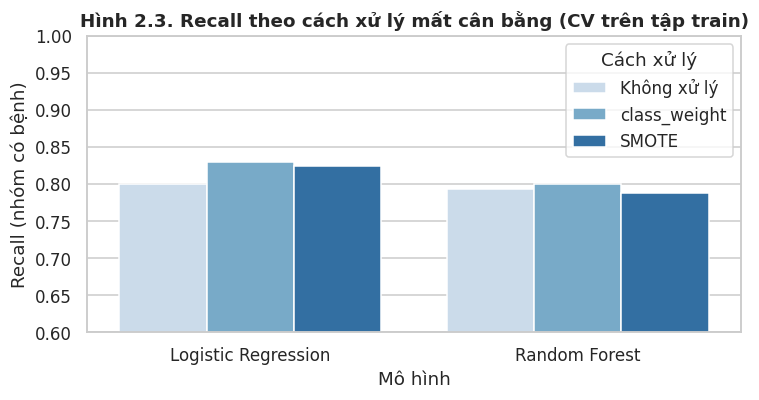

In [10]:
imb.to_csv(ROOT / 'report' / 'bang_so_sanh_mat_can_bang.csv', index=False)
fig, ax = plt.subplots(figsize=(7, 3.8))
sns.barplot(data=imb, x='Mô hình', y='recall', hue='Cách xử lý', ax=ax, palette='Blues')
ax.set_ylim(0.6, 1); ax.set_ylabel('Recall (nhóm có bệnh)'); ax.set_title('Hình 2.3. Recall theo cách xử lý mất cân bằng (CV trên tập train)')
savefig('fig_2_3_so_sanh_mat_can_bang')

## 3. Mã hóa và chuẩn hóa thang đo
- **Biến số** (`age, trestbps, chol, thalach, oldpeak, ca`): `StandardScaler`. Chọn chuẩn hóa z-score vì Logistic Regression (và SVM nếu dùng) nhạy với thang đo; `chol` (~200) và `oldpeak` (~1) chênh nhau hai bậc độ lớn.
- **Biến phân loại không có thứ tự** (`cp, restecg, slope, thal`): `OneHotEncoder`, để mô hình không hiểu nhầm mã 0,1,2,3 là có thứ tự.
- **Biến nhị phân** (`sex, fbs, exang`): giữ nguyên 0/1.
- Toàn bộ nằm trong `ColumnTransformer` (xem `src/common.py`) và được fit **chỉ trên tập train** khi đặt trong Pipeline.

In [11]:
prep = make_preprocessor().fit(X_train)
Xt = prep.transform(X_train)
print('Số cột sau mã hóa:', Xt.shape[1])
print('Trung bình cột số (train, sau chuẩn hóa):', np.round(Xt[:, :6].mean(0), 2))
print('Độ lệch chuẩn:', np.round(Xt[:, :6].std(0), 2))

Số cột sau mã hóa: 22
Trung bình cột số (train, sau chuẩn hóa): [ 0.  0. -0.  0.  0. -0.]
Độ lệch chuẩn: [1. 1. 1. 1. 1. 1.]
